# Fase 2 — Desarrollo, Modelado y Evaluación
## MATERNA · Sistema de alerta temprana de riesgo materno-perinatal (La Guajira y Cesar)
**Proyecto de aula — Inteligencia Artificial · Universidad Popular del Cesar**

Este notebook ejecuta y documenta el pipeline del repositorio (`src/`). Toda la lógica vive en módulos versionados. El notebook solo los orquesta y muestra los resultados, para que lo que se presenta sea exactamente lo que está en el código.

| Sub-fase | Módulo | Contenido |
|---|---|---|
| 2.1 Preprocesamiento | `src/data_preprocessing.py` | Limpieza, imputación estratificada sin fuga, RobustScaler, One-Hot, partición 70/15/15 |
| 2.2 Modelado | `src/train_models.py` | Regresión Logística (baseline), SVM y Random Forest, GridSearchCV con 5-fold estratificado, SMOTE vs. class_weight |
| 2.3 Reglas clínicas | `src/clinical_rules.py` | Motor híbrido `evaluar_riesgo_hibrido()` |
| 2.4 Evaluación | `src/evaluate.py` | Métricas en prueba, IC 95 % bootstrap, matrices de confusión, ROC, costo clínico, auditoría de sesgos |
| 2.5 Pruebas | `tests/` | 129 pruebas automatizadas: reglas, datos, modelos, coherencia clínica, interfaz y navegador |

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2.1 Preprocesamiento

In [2]:
from src.data_preprocessing import cargar_dataset, reporte_calidad, preparar_datos, construir_preprocesador

for clave, valor in reporte_calidad(cargar_dataset()).items():
    print(f"{clave}: {valor}")

X_train, X_val, X_test, y_train, y_val, y_test = preparar_datos()
pd.DataFrame({n: y.value_counts().sort_index() for n, y in [("train", y_train), ("val", y_val), ("test", y_test)]}
             ).rename(index={0: "Bajo", 1: "Medio", 2: "Alto"}).T.assign(total=lambda d: d.sum(axis=1))

registros: 1200
columnas: 16
ids_duplicados: 0
filas_duplicadas_sin_id: 0
nulos: {'fcf_bpm': 89, 'glucosa_mgdl': 159}
pct_nulos: {'fcf_bpm': 7.42, 'glucosa_mgdl': 13.25}
fuera_de_rango_fisiologico: {}
distribucion_target: {'Bajo Riesgo': 578, 'Riesgo Medio': 470, 'Alto Riesgo': 152}


riesgo_obstetrico,Bajo,Medio,Alto,total
train,405,329,106,840
val,86,71,23,180
test,87,70,23,180


**Decisiones de preprocesamiento**
- **Imputación** de `glucosa_mgdl` y `fcf_bpm` con la mediana del estrato *área de residencia × trimestre*, como se definió en el documento de la Fase 1. Si el estrato tiene menos de 10 observaciones, se usa la mediana por área y, si no alcanza, la global. Las medianas se aprenden **solo con entrenamiento**, porque el imputador es un paso del Pipeline.
- **Indicadores** `glucosa_no_disponible` y `fcf_no_disponible`: en campo, la falta de glucómetro o doppler fetal es información sobre el acceso.
- **RobustScaler** sobre las 7 variables continuas, para que las crisis hipertensivas reales no distorsionen la escala.
- **One-Hot** solo en las variables de acceso (`area_residencia`, `atendido_por`). Departamento, municipio y etnia **no** entran al modelo: no mejoran el desempeño (ver ablación) y su inclusión podría convertir la identidad étnica en un *proxy* de riesgo.
- **Target ordinal:** Bajo → 0, Medio → 1, Alto → 2.

In [3]:
pre = construir_preprocesador().fit(X_train)
Xt = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out())
print("Matriz de entrenamiento transformada:", Xt.shape)
imp = pre.named_steps["imputacion"]
print("\nMedianas de imputación aprendidas (estrato -> valor):")
for col in imp.columnas:
    print(" ", col, {f"{a}/{t}": round(v, 1) for (a, t), v in imp.mediana_estrato_[col].items()})
Xt.head()

Matriz de entrenamiento transformada: (840, 17)

Medianas de imputación aprendidas (estrato -> valor):
  glucosa_mgdl {'Cabecera/T2': 102.4, 'Cabecera/T3': 96.3, 'Rural disperso/T1': 101.3, 'Rural disperso/T2': 97.2, 'Rural disperso/T3': 99.6}
  fcf_bpm {'Cabecera/T2': 139.8, 'Cabecera/T3': 139.8, 'Rural disperso/T1': 146.2, 'Rural disperso/T2': 140.5, 'Rural disperso/T3': 139.0}


,edad,semanas_gestacion,n_controles_prenatales,pas_mmhg,pad_mmhg,fcf_bpm,glucosa_mgdl,proteinuria,convulsiones,glucosa_no_disponible,fcf_no_disponible,area_residencia_Cabecera,area_residencia_Rural disperso,atendido_por_Auxiliar de enfermeria,atendido_por_Enfermero(a),atendido_por_Medico,atendido_por_Partera tradicional
0,0.666667,-0.444444,0.25,-0.176471,0.000000,0.499248,0.099187,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.444444,0.444444,0.00,-0.235294,1.636364,0.324812,2.414634,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.111111,0.888889,0.25,-1.058824,-0.363636,1.275188,3.182114,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.000000,0.222222,0.25,-0.352941,-0.727273,0.896241,-1.279675,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,-1.222222,0.000000,0.00,-0.823529,0.090909,0.000000,0.066667,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0


## 2.2 Experimentación y entrenamiento
- **Baseline:** Regresión Logística multinomial (lbfgs), con C en 13 valores de 10⁻³ a 10³.
- **Modelo avanzado 1:** SVM con kernels `rbf`, `linear` y `poly`; C ∈ {0.1, 1, 10, 100}; γ ∈ {scale, 0.01, 0.1, 1}; grado ∈ {2, 3}.
- **Modelo avanzado 2 (seleccionado):** Random Forest con 300 árboles; profundidad máxima ∈ {None, 8, 12}; hojas mínimas ∈ {1, 3, 5}; variables por división ∈ {sqrt, 50 %}. Se agregó después de que las pruebas de coherencia clínica (sección 2.5) mostraran que el SVM clasificaba como Bajo Riesgo casos con un único factor de riesgo cerca del umbral.
- **Balanceo como hiperparámetro:** (a) SMOTE dentro de cada fold o (b) `class_weight='balanced'`. No se combinan, para no compensar el desbalance dos veces.
- **Validación cruzada:** 5-fold estratificada sobre entrenamiento. La configuración se elige por **F1-macro** y se registra también el recall de Alto Riesgo.
- **Probabilidades del SVM:** `SVC(probability=True)` está deprecado en scikit-learn 1.9, así que se calibra con `CalibratedClassifierCV` (sigmoide, 5 folds).

La celda siguiente ejecuta la búsqueda completa: 166 configuraciones × 5 folds, en unos dos minutos.

In [4]:
from src.train_models import entrenar_todo
modelos = entrenar_todo()

[Regresión Logística] 26 configuraciones x 5 folds en 17.7 s
[Regresión Logística] mejor f1_macro CV = 0.7499 | {'balanceo': 'class_weight', 'C': np.float64(10.0)}


[SVM] 104 configuraciones x 5 folds en 26.9 s
[SVM] mejor f1_macro CV = 0.8608 | {'balanceo': 'class_weight', 'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}


[Random Forest] 36 configuraciones x 5 folds en 56.7 s
[Random Forest] mejor f1_macro CV = 0.9318 | {'balanceo': 'SMOTE', 'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}

Comparación en validación cruzada (mejor configuración por modelo y estrategia):
             modelo     balanceo                                                                      hiperparametros  cv_f1_macro_media  cv_f1_macro_std  cv_f1_weighted_media  cv_f1_weighted_std  cv_balanced_accuracy_media  cv_balanced_accuracy_std  cv_accuracy_media  cv_accuracy_std  cv_recall_alto_media  cv_recall_alto_std  cv_precision_alto_media  cv_precision_alto_std  cv_f1_alto_media  cv_f1_alto_std  tiempo_ajuste_s
      Random Forest        SMOTE {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 300}             0.9318           0.0171                0.9582              0.0102                      0.9310                    0.0240             0.9583           0.0100


Ablación de variables demográficas:
              modelo                        variables  cv_f1_macro_media  cv_recall_alto_media  cv_balanced_accuracy_media
Regresión Logística  clínicas + acceso (por defecto)             0.7499                0.9065                      0.7633
Regresión Logística clínicas + acceso + demográficas             0.7273                0.8597                      0.7401
                SVM  clínicas + acceso (por defecto)             0.8608                0.8316                      0.8569
                SVM clínicas + acceso + demográficas             0.8279                0.7662                      0.8215
      Random Forest  clínicas + acceso (por defecto)             0.9318                0.8502                      0.9310
      Random Forest clínicas + acceso + demográficas             0.9302                0.8312                      0.9259


In [5]:
from src.config import DIR_METRICAS
comparacion = pd.read_csv(DIR_METRICAS / "comparacion_cv_por_estrategia.csv")
cols = ["modelo", "balanceo", "hiperparametros", "cv_f1_macro_media", "cv_f1_macro_std", "cv_balanced_accuracy_media",
        "cv_recall_alto_media", "cv_recall_alto_std", "cv_precision_alto_media", "tiempo_ajuste_s"]
comparacion[cols]

,modelo,balanceo,hiperparametros,cv_f1_macro_media,cv_f1_macro_std,cv_balanced_accuracy_media,cv_recall_alto_media,cv_recall_alto_std,cv_precision_alto_media,tiempo_ajuste_s
0,Random Forest,SMOTE,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.9318,0.0171,0.9310,0.8502,0.0887,0.8674,2.6530
1,Random Forest,class_weight,"{'max_depth': 12, 'max_features': 0.5, 'min_sa...",0.9261,0.0202,0.9238,0.8316,0.0881,0.8600,2.3358
2,SVM,class_weight,"{'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}",0.8608,0.0110,0.8569,0.8316,0.0771,0.8871,0.1627
3,SVM,SMOTE,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.8454,0.0296,0.8460,0.8411,0.0825,0.8525,0.1610
4,Regresión Logística,class_weight,{'C': np.float64(10.0)},0.7499,0.0129,0.7633,0.9065,0.0649,0.8134,0.1800
5,Regresión Logística,SMOTE,{'C': np.float64(0.3162)},0.7467,0.0330,0.7582,0.8965,0.0343,0.8166,0.1315


In [6]:
exp = pd.read_csv(DIR_METRICAS / "experimentos_cv_completo.csv")
print(f"Registro completo: {len(exp)} configuraciones evaluadas")
exp[exp["modelo"] == "SVM"].groupby(["kernel", "balanceo"])[["cv_f1_macro_media", "cv_recall_alto_media", "tiempo_ajuste_s"]].max().round(4)

Registro completo: 166 configuraciones evaluadas


cv_f1_macro_media  cv_recall_alto_media  tiempo_ajuste_s
kernel balanceo                                                              
linear SMOTE                    0.7542                0.8874           1.7359
       class_weight             0.7527                0.8874           0.9977
poly   SMOTE                    0.8401                0.8407           3.9828
       class_weight             0.8374                0.8502           2.3442
rbf    SMOTE                    0.8454                0.8788           0.3929
       class_weight             0.8608                0.8874           0.2091

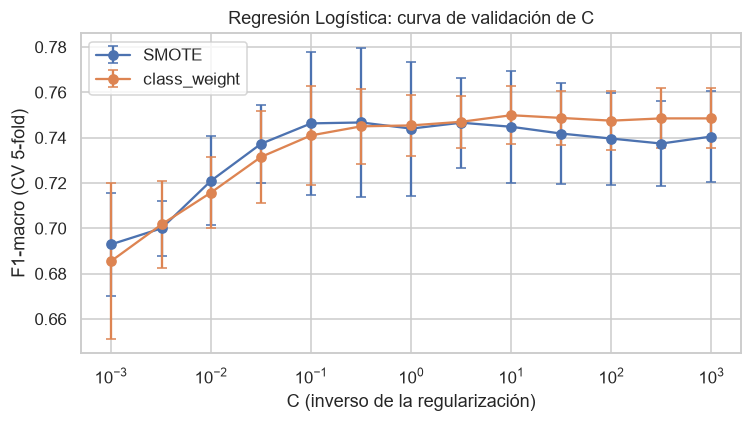

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
lr = exp[exp["modelo"] == "Regresión Logística"]
for estrategia, grupo in lr.groupby("balanceo"):
    grupo = grupo.sort_values("C")
    ax.errorbar(grupo["C"], grupo["cv_f1_macro_media"], yerr=grupo["cv_f1_macro_std"], marker="o", capsize=3, label=estrategia)
ax.set_xscale("log"); ax.set_xlabel("C (inverso de la regularización)"); ax.set_ylabel("F1-macro (CV 5-fold)")
ax.set_title("Regresión Logística: curva de validación de C"); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
pd.read_csv(DIR_METRICAS / "ablacion_variables_demograficas.csv")

,modelo,variables,cv_f1_macro_media,cv_recall_alto_media,cv_balanced_accuracy_media
0,Regresión Logística,clínicas + acceso (por defecto),0.7499,0.9065,0.7633
1,Regresión Logística,clínicas + acceso + demográficas,0.7273,0.8597,0.7401
2,SVM,clínicas + acceso (por defecto),0.8608,0.8316,0.8569
3,SVM,clínicas + acceso + demográficas,0.8279,0.7662,0.8215
4,Random Forest,clínicas + acceso (por defecto),0.9318,0.8502,0.9310
5,Random Forest,clínicas + acceso + demográficas,0.9302,0.8312,0.9259


**Lectura de la experimentación**
- **Random Forest es el mejor modelo en CV** (F1-macro ≈ 0,93, frente a ≈ 0,86 del SVM y ≈ 0,75 de la Regresión Logística). Las etiquetas dependen de umbrales en cada variable, y los árboles representan umbrales de forma nativa.
- La Regresión Logística tiene **mayor recall en Alto Riesgo** en CV, a costa de una precisión menor: alerta más, pero con más falsos positivos.
- SMOTE y `class_weight` rinden de forma parecida. Gana SMOTE en Random Forest y `class_weight` en SVM y Regresión Logística.
- El mejor C del SVM (100) está en el **borde de la grilla** pedida. No se amplió porque el SVM ya no es el modelo principal.
- Agregar las variables demográficas **no mejora** a ningún modelo, lo que confirma la decisión de excluirlas.

## 2.3 Motor híbrido de reglas clínicas

In [9]:
from src.clinical_rules import evaluar_riesgo_hibrido, UMBRAL_PAS_SEVERA, UMBRAL_PAD_SEVERA, UMBRAL_PROTEINURIA
print(f"Reglas: PAS >= {UMBRAL_PAS_SEVERA} | PAD >= {UMBRAL_PAD_SEVERA} | convulsiones | proteinuria >= {UMBRAL_PROTEINURIA} (++)")

casos = {
    "Emergencia (Uribia, sin doppler)": dict(edad=26, departamento="La Guajira", municipio="Uribia", pertenencia_etnica="Wayuu",
        area_residencia="Rural disperso", semanas_gestacion=31, n_controles_prenatales=1, atendido_por="Partera tradicional",
        pas_mmhg=165, pad_mmhg=108, fcf_bpm=None, glucosa_mgdl=110.5, proteinuria=2, convulsiones=1),
    "Adolescente sin controles (Manaure)": dict(edad=17, departamento="La Guajira", municipio="Manaure", pertenencia_etnica="Wayuu",
        area_residencia="Rural disperso", semanas_gestacion=24, n_controles_prenatales=0, atendido_por="Auxiliar de enfermeria",
        pas_mmhg=128, pad_mmhg=82, fcf_bpm=150.0, glucosa_mgdl=None, proteinuria=0, convulsiones=0),
    "Control de rutina (Valledupar)": dict(edad=27, departamento="Cesar", municipio="Valledupar", pertenencia_etnica="Mestiza",
        area_residencia="Cabecera", semanas_gestacion=28, n_controles_prenatales=5, atendido_por="Medico",
        pas_mmhg=110, pad_mmhg=70, fcf_bpm=142.0, glucosa_mgdl=88.0, proteinuria=0, convulsiones=0),
}
filas = []
for nombre, registro in casos.items():
    r = evaluar_riesgo_hibrido(registro, modelos["Random Forest"])
    filas.append({"caso": nombre, "categoría final": r.categoria, "origen": r.origen, "predicción RF": r.categoria_modelo,
                  **{f"P({k})": round(v, 3) for k, v in r.probabilidades_modelo.items()}, "alertas": "; ".join(r.alertas)})
pd.DataFrame(filas)

Reglas: PAS >= 160 | PAD >= 110 | convulsiones | proteinuria >= 2 (++)


,caso,categoría final,origen,predicción RF,P(Bajo Riesgo),P(Riesgo Medio),P(Alto Riesgo),alertas
0,"Emergencia (Uribia, sin doppler)",Alto Riesgo,regla_clinica,Alto Riesgo,0.000,0.027,0.973,Hipertensión severa: PAS 165 mmHg (umbral ≥ 16...
1,Adolescente sin controles (Manaure),Riesgo Medio,modelo_ml,Riesgo Medio,0.017,0.913,0.070,
2,Control de rutina (Valledupar),Bajo Riesgo,modelo_ml,Bajo Riesgo,1.000,0.000,0.000,


## 2.4 Evaluación en datos no vistos

In [10]:
from src.evaluate import evaluar_todo
tabla_test, tabla_sin_reglas, subgrupos, resumen = evaluar_todo()

VALIDACIÓN (n=180):
                                         accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  roc_auc_ovr_macro  recall_alto  falsos_negativos_alto  alto_clasificado_como_bajo  costo_clinico_total
sistema                                                                                                                                                                                                       
Regresión Logística                        0.717            0.710         0.768     0.732        0.713              0.862        0.957                      1                           0                   95
SVM                                        0.844            0.847         0.836     0.841        0.843              0.957        0.826                      4                           0                   70
Random Forest                              0.967            0.937         0.952     0.944        0.967              0.995        0.913                 

In [11]:
cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "roc_auc_ovr_macro",
        "recall_alto", "precision_alto", "falsos_negativos_alto", "alto_clasificado_como_bajo", "costo_clinico_total",
        "recall_alto_ic95", "f1_macro_ic95"]
tabla_test[cols].round(3)

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr_macro,recall_alto,precision_alto,falsos_negativos_alto,alto_clasificado_como_bajo,costo_clinico_total,recall_alto_ic95,f1_macro_ic95
sistema,,,,,,,,,,,,,
Regresión Logística,0.722,0.705,0.751,0.724,0.721,0.854,0.870,0.667,3,0,99,"[0.700, 1.000]","[0.644, 0.788]"
SVM,0.856,0.858,0.841,0.846,0.857,0.961,0.783,0.857,5,0,54,"[0.593, 0.944]","[0.776, 0.899]"
Random Forest,0.961,0.947,0.939,0.943,0.961,0.988,0.870,0.909,3,0,19,"[0.708, 1.000]","[0.892, 0.981]"
Híbrido (Regresión Logística + reglas),0.733,0.719,0.780,0.742,0.730,0.864,0.957,0.688,1,0,89,"[0.852, 1.000]","[0.670, 0.801]"
Híbrido (SVM + reglas),0.878,0.879,0.899,0.886,0.878,0.972,0.957,0.880,1,0,34,"[0.852, 1.000]","[0.828, 0.932]"
Híbrido (Random Forest + reglas),0.972,0.958,0.968,0.963,0.972,0.998,0.957,0.917,1,0,9,"[0.857, 1.000]","[0.923, 0.992]"


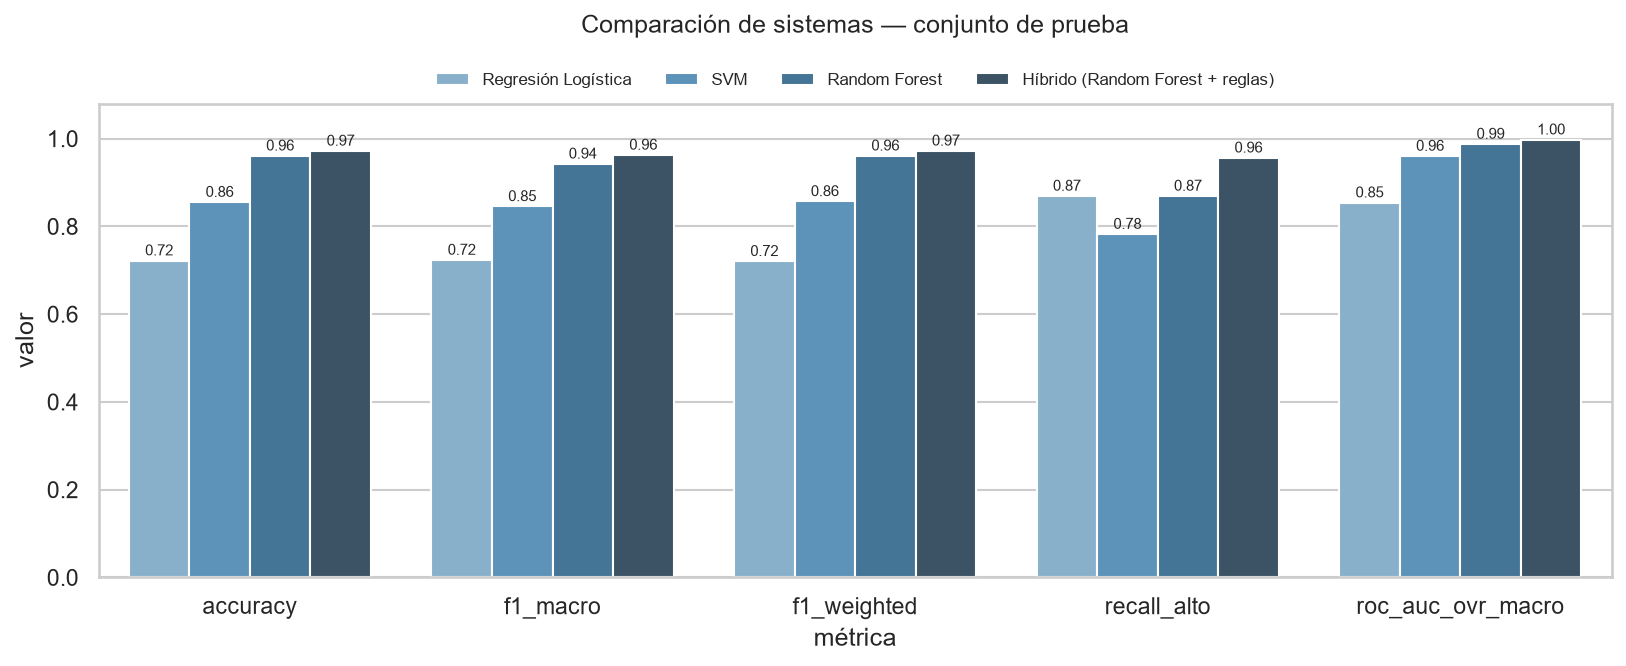

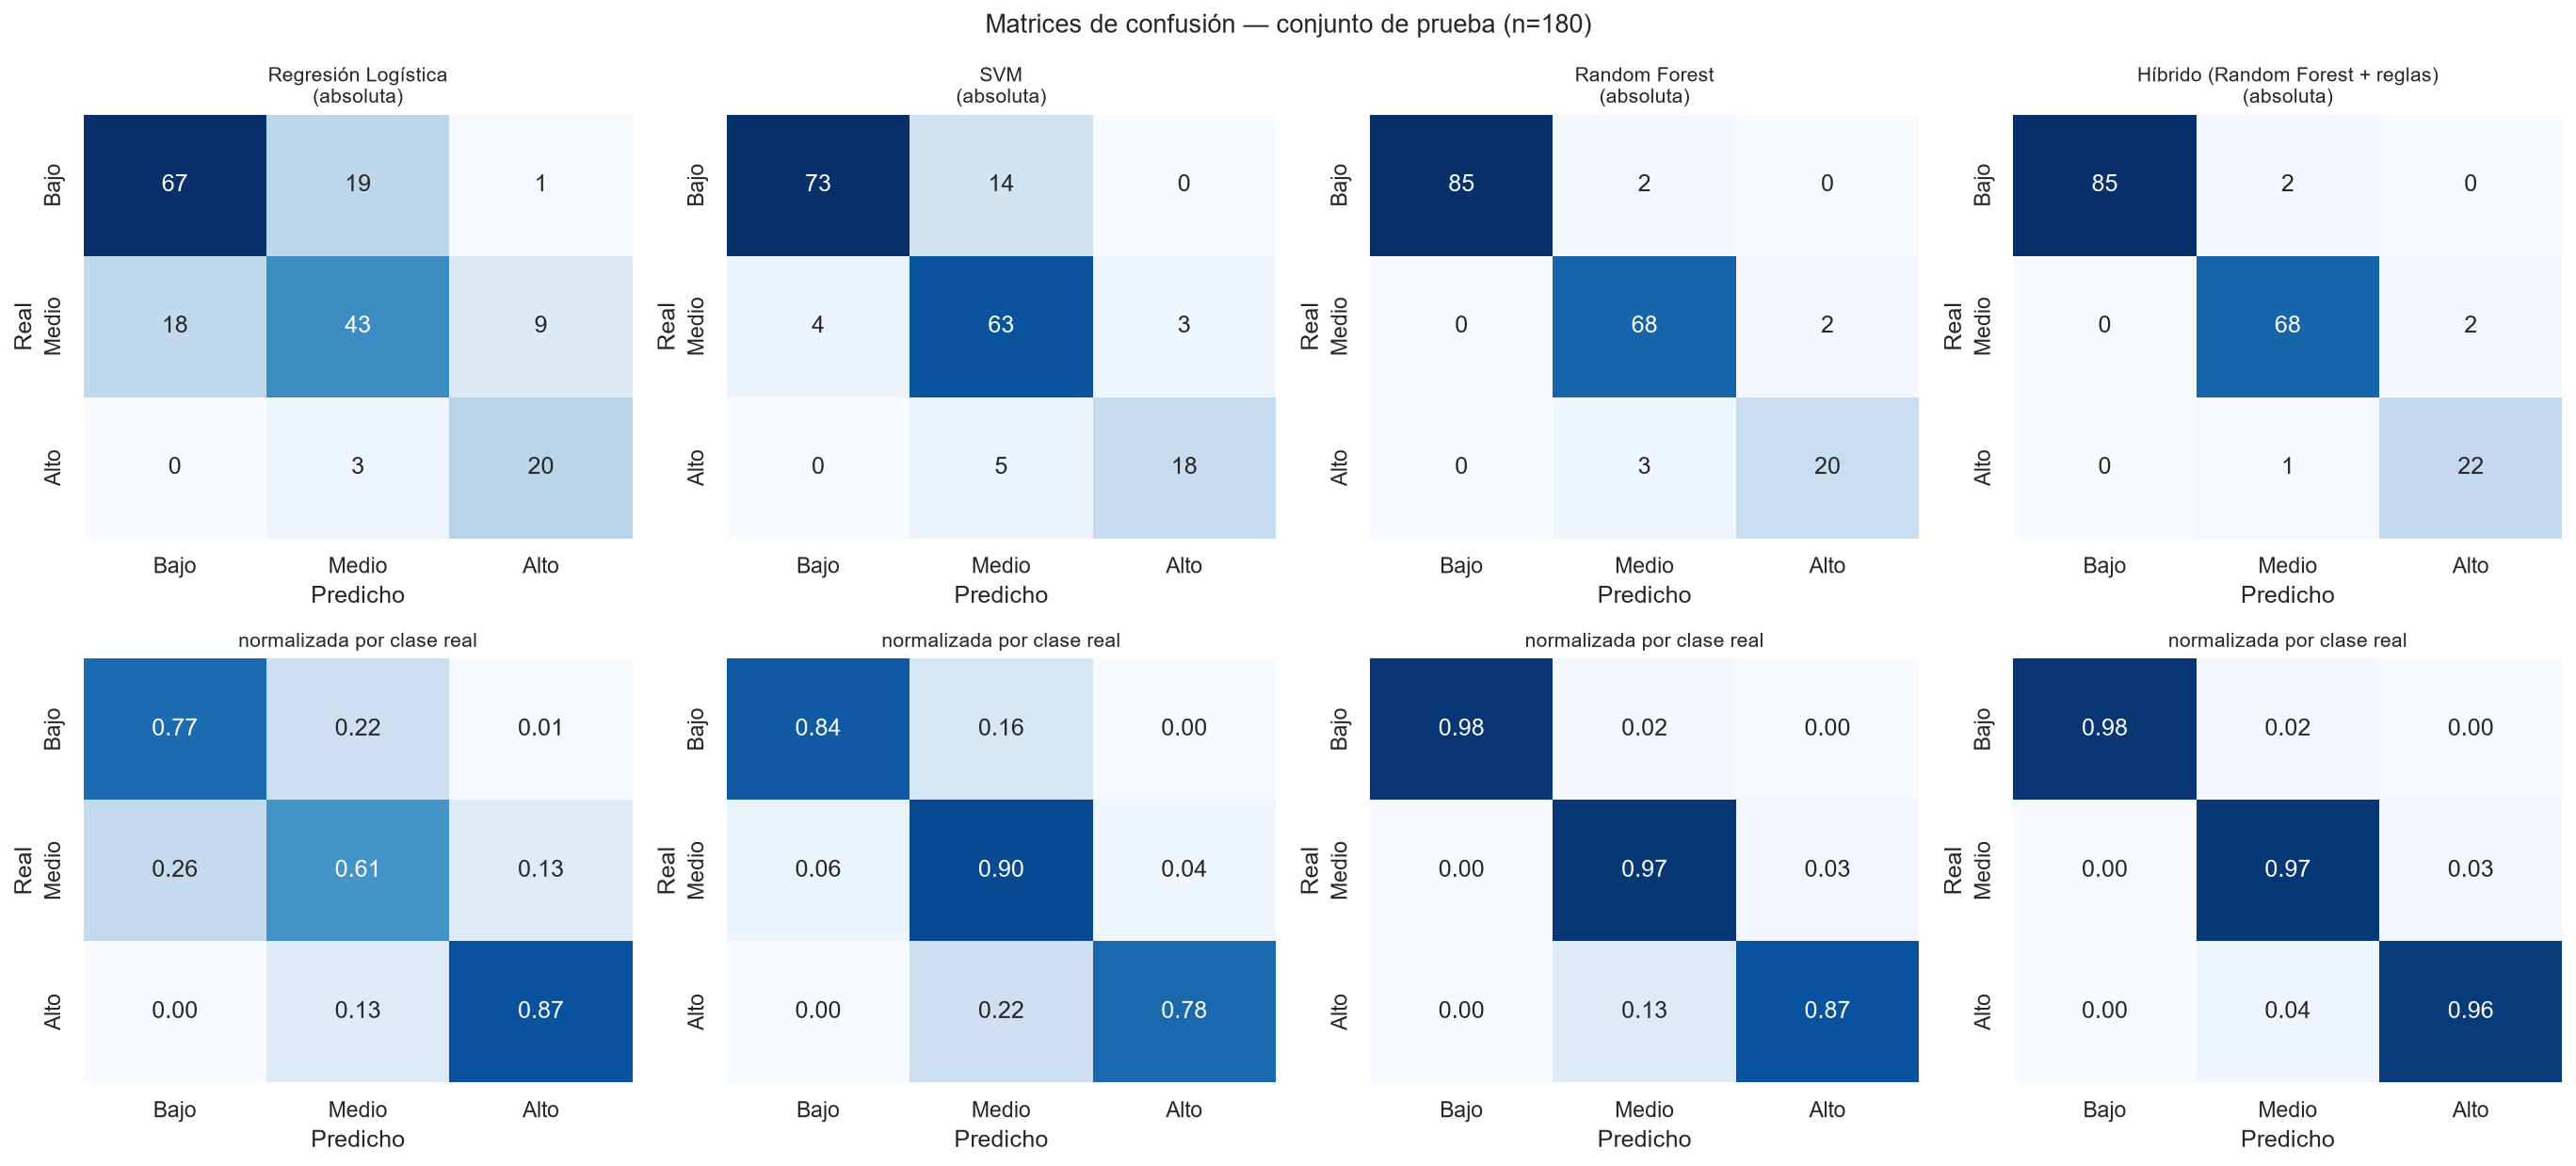

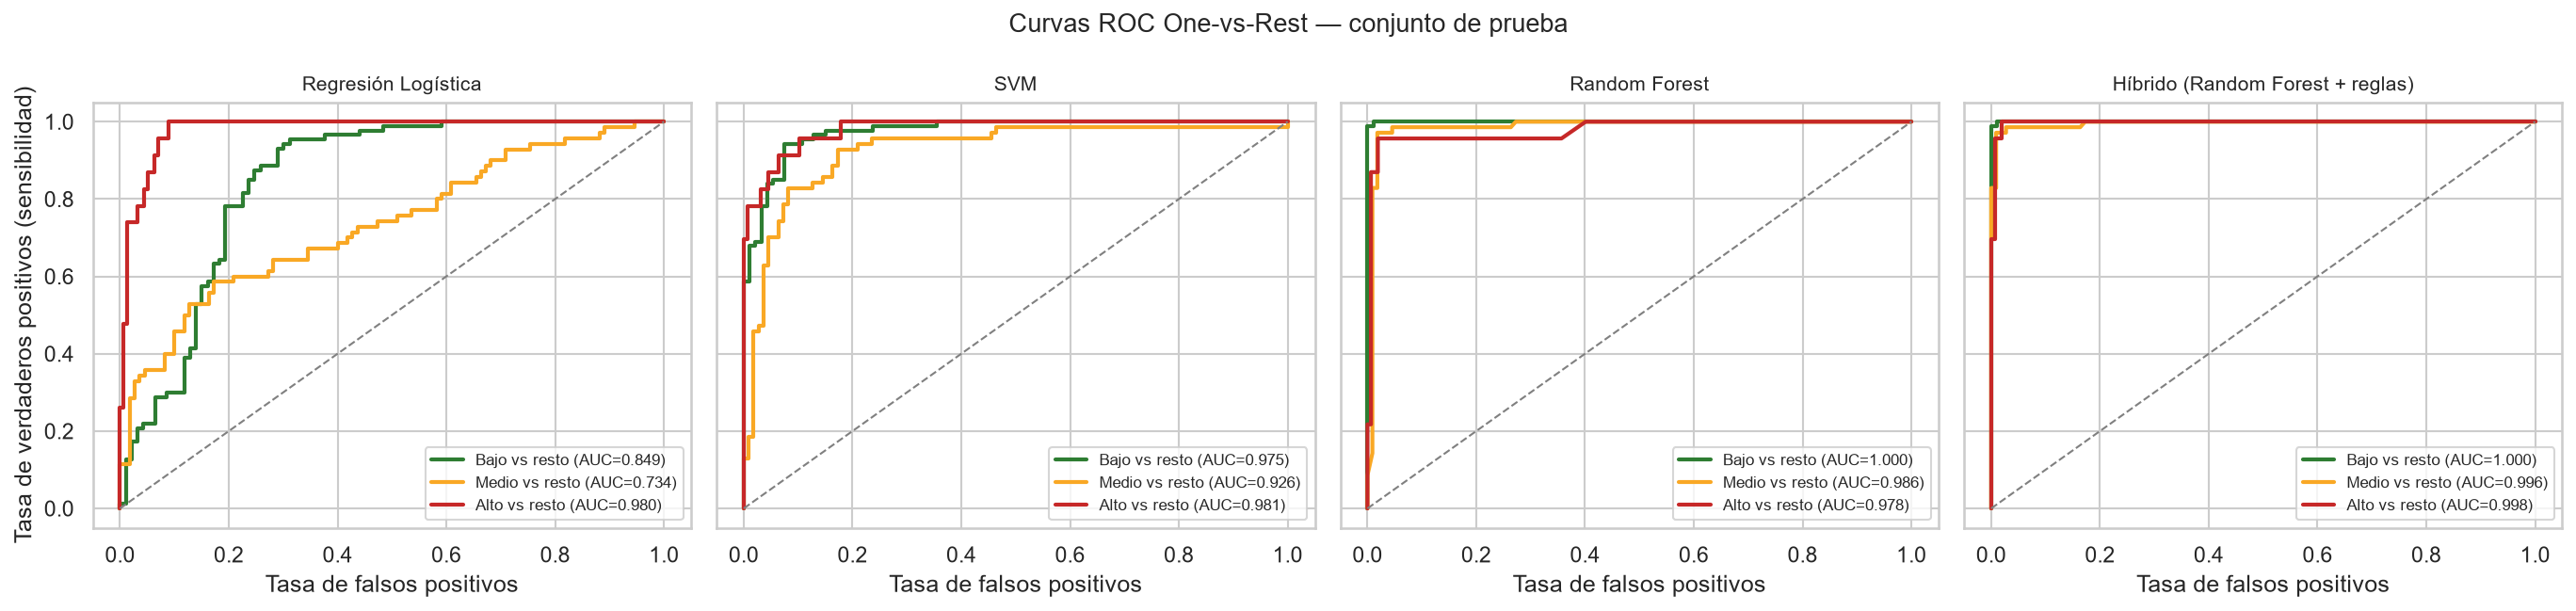

In [12]:
from src.config import DIR_FIGURAS
display(Image(DIR_FIGURAS / "comparacion_sistemas_test.png", width=900))
display(Image(DIR_FIGURAS / "matrices_confusion_test.png", width=1000))
display(Image(DIR_FIGURAS / "curvas_roc_test.png", width=1000))

### Desempeño en el subconjunto sin signos críticos (aporte real del modelo)

In [13]:
tabla_sin_reglas[["n", "accuracy", "f1_macro", "recall_alto", "precision_alto", "falsos_negativos_alto", "costo_clinico_total"]].round(3)

,n,accuracy,f1_macro,recall_alto,precision_alto,falsos_negativos_alto,costo_clinico_total
sistema,,,,,,,
Regresión Logística,166,0.711,0.673,0.889,0.444,1,89
SVM,166,0.867,0.847,0.889,0.727,1,34
Random Forest,166,0.970,0.932,0.889,0.800,1,9
Híbrido (Regresión Logística + reglas),166,0.711,0.673,0.889,0.444,1,89
Híbrido (SVM + reglas),166,0.867,0.847,0.889,0.727,1,34
Híbrido (Random Forest + reglas),166,0.970,0.932,0.889,0.800,1,9


### Costo clínico del error
La matriz de costo ilustrativa (filas = real, columnas = predicho) penaliza más la **subestimación** del riesgo:

| real \ predicho | Bajo | Medio | Alto |
|---|---|---|---|
| **Bajo** | 0 | 1 | 2 |
| **Medio** | 3 | 0 | 1 |
| **Alto** | **10** | **5** | 0 |

Los pesos son un supuesto del equipo y no un estándar oficial. Su propósito es ordenar los sistemas según el daño potencial de sus errores.

### Auditoría de sesgos por subgrupo (predicción fuera de fold sobre los 1.200 registros)

In [14]:
subgrupos.drop(columns="sistema")

,variable,grupo,n,n_alto_real,accuracy,f1_macro,recall_alto
0,area_residencia,Cabecera,499,71,0.978,0.966,0.944
1,area_residencia,Rural disperso,701,81,0.964,0.938,0.877
2,pertenencia_etnica,Afro,120,13,0.983,0.970,1.000
3,pertenencia_etnica,Arhuaco,31,5,1.000,1.000,1.000
4,pertenencia_etnica,Kogui,20,2,1.000,1.000,1.000
5,pertenencia_etnica,Mestiza,370,47,0.978,0.964,0.894
6,pertenencia_etnica,Wayuu,564,70,0.963,0.940,0.900
7,pertenencia_etnica,Wiwa,20,4,0.950,0.930,0.750
8,pertenencia_etnica,Yukpa,75,11,0.947,0.915,0.909
9,departamento,Cesar,431,52,0.979,0.963,0.923


## 2.5 Pruebas de coherencia clínica y suite automatizada
Las métricas globales no muestran si el modelo responde con sentido clínico a cada variable. Por eso se partió de una gestante sana y se cambió **una sola variable** a la vez. La referencia es el propio dataset: ninguna de las 578 gestantes de Bajo Riesgo tiene un solo factor de riesgo, así que un factor aislado debe dar al menos Riesgo Medio.

In [15]:
sys.path.insert(0, str(RAIZ / "tests"))
from conftest import REGISTRO_SANO, a_dataframe
from test_coherencia_clinica import FACTOR_UNICO

clases = np.array(["Bajo", "Medio", "Alto"])
filas = []
for nombre, cambios in [("Gestante sana (referencia)", {})] + FACTOR_UNICO + [("20 controles (fuera de rango)", {"n_controles_prenatales": 20})]:
    X = a_dataframe([{**REGISTRO_SANO, **cambios}])
    filas.append({"caso": nombre, **{m: clases[modelos[m].predict_proba(X)[0].argmax()] for m in modelos}})
coherencia = pd.DataFrame(filas).set_index("caso")
coherencia.style.map(lambda v: "background-color:#F6D5D9" if v == "Bajo" else "")

,Regresión Logística,SVM,Random Forest
caso,,,
Gestante sana (referencia),Bajo,Bajo,Bajo
HTA sistólica 140,Bajo,Bajo,Medio
HTA sistólica 145,Bajo,Bajo,Medio
HTA diastólica 90,Bajo,Bajo,Medio
HTA diastólica 95,Bajo,Bajo,Medio
Glucosa 140,Medio,Bajo,Medio
Glucosa 145,Medio,Bajo,Medio
FCF 105 (bradicardia),Bajo,Medio,Medio
FCF 165 (taquicardia),Bajo,Bajo,Medio


El SVM clasifica como **Bajo** casos que deberían ser al menos Medio: hipertensión de 140/90 a 145/95, glucosa de 140 a 145, FCF de 165, edad de 36 y **cero controles prenatales**. Además, extrapola a Alto Riesgo con 20 controles, un valor fuera del rango de entrenamiento. El Random Forest pasa todos los casos. Este hallazgo motivó su incorporación y se alinea con la brecha rural, porque en el área rural la ausencia de controles es 3,6 veces más frecuente.

La suite completa (`pytest`) verifica reglas, datos, modelos, coherencia clínica e interfaz:

In [16]:
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "-m", "not e2e"], cwd=RAIZ, capture_output=True, text=True)
print(r.stdout.strip().splitlines()[-1])

123 passed, 6 deselected in 55.99s


## Conclusiones de la Fase 2
1. **El sistema híbrido Random Forest + reglas es el mejor** en el conjunto de prueba: F1-macro 0,963 (IC 95 % 0,92–0,99), recall de Alto Riesgo 0,957 (22 de 23), ROC-AUC macro 0,998 y el menor costo clínico (9, frente a 34 del híbrido SVM y 99 del baseline). Se eligió por validación (F1-macro 0,944), sin usar el conjunto de prueba.
2. **Las reglas siguen aportando.** Por sí solo, el Random Forest deja escapar 3 de 23 casos de Alto Riesgo; las reglas recuperan 2. El falso negativo que queda es una gestante sin signos críticos que el modelo clasificó como Riesgo Medio. Ningún caso de Alto Riesgo se clasificó como Bajo.
3. **Rendimiento honesto.** En los 166 casos de prueba sin signos críticos, el Random Forest obtiene un F1-macro de 0,932, frente a 0,847 del SVM y 0,673 de la Regresión Logística.
4. **Las pruebas cambiaron el modelo.** Las pruebas de coherencia clínica detectaron que el SVM ignoraba factores de riesgo aislados, en particular la ausencia de controles prenatales. Con el Random Forest, la sensibilidad en el área rural dispersa subió de 0,78 a 0,88. Sigue por debajo de la cabecera (0,94), y la atención por auxiliares de enfermería es el subgrupo más bajo (0,64, con solo 11 casos de Alto Riesgo).
5. **Limitación principal.** Los datos son sintéticos y las etiquetas siguen umbrales deterministas, que es justo lo que los árboles aprenden mejor. Parte de la ventaja del Random Forest puede deberse a esa estructura. Antes de cualquier uso clínico se necesita validar el modelo con datos reales anonimizados y con criterio de un especialista.